In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.svm import SVC
import joblib

df = pd.read_csv(r"C:\Users\osman\Downloads\detect_dataset.csv")

print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst five rows:")
display(df.head())

Dataset shape: (12001, 9)

Column names:
['Output (S)', 'Ia', 'Ib', 'Ic', 'Va', 'Vb', 'Vc', 'Unnamed: 7', 'Unnamed: 8']

First five rows:


,Output (S),Ia,Ib,Ic,Va,Vb,Vc,Unnamed: 7,Unnamed: 8
0,0,-170.472196,9.219613,161.252583,0.054490,-0.659921,0.605431,NaN,NaN
1,0,-122.235754,6.168667,116.067087,0.102000,-0.628612,0.526202,NaN,NaN
2,0,-90.161474,3.813632,86.347841,0.141026,-0.605277,0.464251,NaN,NaN
3,0,-79.904916,2.398803,77.506112,0.156272,-0.602235,0.445963,NaN,NaN
4,0,-63.885255,0.590667,63.294587,0.180451,-0.591501,0.411050,NaN,NaN


In [2]:
#Cleaning the dataset
print("Data types before cleaning:")
print(df.dtypes)

print("\nMissing values before cleaning:")
print(df.isnull().sum())

# Remove columns containing no information
empty_columns = [
    col for col in df.columns
    if df[col].isnull().all()
]

print("\nColumns removed:", empty_columns)

df = df.drop(columns=empty_columns)

# Rename the label column
df = df.rename(columns={"Output (S)": "fault"})

# Check measurement columns are numeric
features = ["Ia", "Ib", "Ic", "Va", "Vb", "Vc"]

for col in features:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Remove rows with missing values, if any
df = df.dropna(subset=["fault"] + features).copy()

df["fault"] = df["fault"].astype(int)

print("\nShape after cleaning:", df.shape)

print("\nFinal columns:")
print(df.columns.tolist())

print("\nMissing values after cleaning:")
print(df.isnull().sum())

print("\nFinal data types:")
print(df.dtypes)

Data types before cleaning:
Output (S)      int64
Ia            float64
Ib            float64
Ic            float64
Va            float64
Vb            float64
Vc            float64
Unnamed: 7    float64
Unnamed: 8    float64
dtype: object

Missing values before cleaning:
Output (S)        0
Ia                0
Ib                0
Ic                0
Va                0
Vb                0
Vc                0
Unnamed: 7    12001
Unnamed: 8    12001
dtype: int64

Columns removed: ['Unnamed: 7', 'Unnamed: 8']

Shape after cleaning: (12001, 7)

Final columns:
['fault', 'Ia', 'Ib', 'Ic', 'Va', 'Vb', 'Vc']

Missing values after cleaning:
fault    0
Ia       0
Ib       0
Ic       0
Va       0
Vb       0
Vc       0
dtype: int64

Final data types:
fault      int64
Ia       float64
Ib       float64
Ic       float64
Va       float64
Vb       float64
Vc       float64
dtype: object


In [3]:
fault_counts = df["fault"].value_counts().sort_index()

print("No-fault rows (0):", fault_counts.get(0, 0))
print("Fault rows (1):", fault_counts.get(1, 0))

print("\nClass distribution:")
display(fault_counts.rename(index={
    0: "No fault",
    1: "Fault"
}).to_frame("Number of rows"))

No-fault rows (0): 6505
Fault rows (1): 5496

Class distribution:


,Number of rows
fault,
No fault,6505
Fault,5496


In [4]:
rng = np.random.default_rng(42)

idx = rng.permutation(len(df))

n_train = int(0.6 * len(df))
n_val = int(0.2 * len(df))

train_idx = idx[:n_train]
val_idx = idx[n_train:n_train + n_val]
test_idx = idx[n_train + n_val:]

train_df = df.iloc[train_idx].copy()
val_df = df.iloc[val_idx].copy()
test_df = df.iloc[test_idx].copy()

print("Training rows:", len(train_df))
print("Validation rows:", len(val_df))
print("Testing rows:", len(test_df))

Training rows: 7200
Validation rows: 2400
Testing rows: 2401


In [5]:
for name, part in [
    ("Training", train_df),
    ("Validation", val_df),
    ("Testing", test_df)
]:
    print(
        name,
        "| Rows:", len(part),
        "| Fault fraction:", round(part["fault"].mean(), 4),
        "| Fault rows:", int(part["fault"].sum())
    )

Training | Rows: 7200 | Fault fraction: 0.4607 | Fault rows: 3317
Validation | Rows: 2400 | Fault fraction: 0.4512 | Fault rows: 1083
Testing | Rows: 2401 | Fault fraction: 0.4565 | Fault rows: 1096


In [6]:
X_train_raw = train_df[features].to_numpy(dtype=float)
X_val_raw = val_df[features].to_numpy(dtype=float)
X_test_raw = test_df[features].to_numpy(dtype=float)

y_train = train_df["fault"].to_numpy(dtype=int)
y_val = val_df["fault"].to_numpy(dtype=int)
y_test = test_df["fault"].to_numpy(dtype=int)

# Statistics from training data only
train_mean = X_train_raw.mean(axis=0)
train_std = X_train_raw.std(axis=0)

# Protect against division by zero
train_std[train_std == 0] = 1.0

# Standardise all three splits with training statistics
X_train = (X_train_raw - train_mean) / train_std
X_val = (X_val_raw - train_mean) / train_std
X_test = (X_test_raw - train_mean) / train_std

print("Training feature means:")
print(X_train.mean(axis=0))

print("\nTraining feature standard deviations:")
print(X_train.std(axis=0))

Training feature means:
[-1.57898386e-17  1.13489465e-17  1.77635684e-17  9.86864911e-18
 -1.48029737e-17 -3.57738530e-17]

Training feature standard deviations:
[1. 1. 1. 1. 1. 1.]


In [7]:
np.savez(
    "scaling_stats.npz",
    mean=train_mean,
    std=train_std,
    features=np.array(features)
)

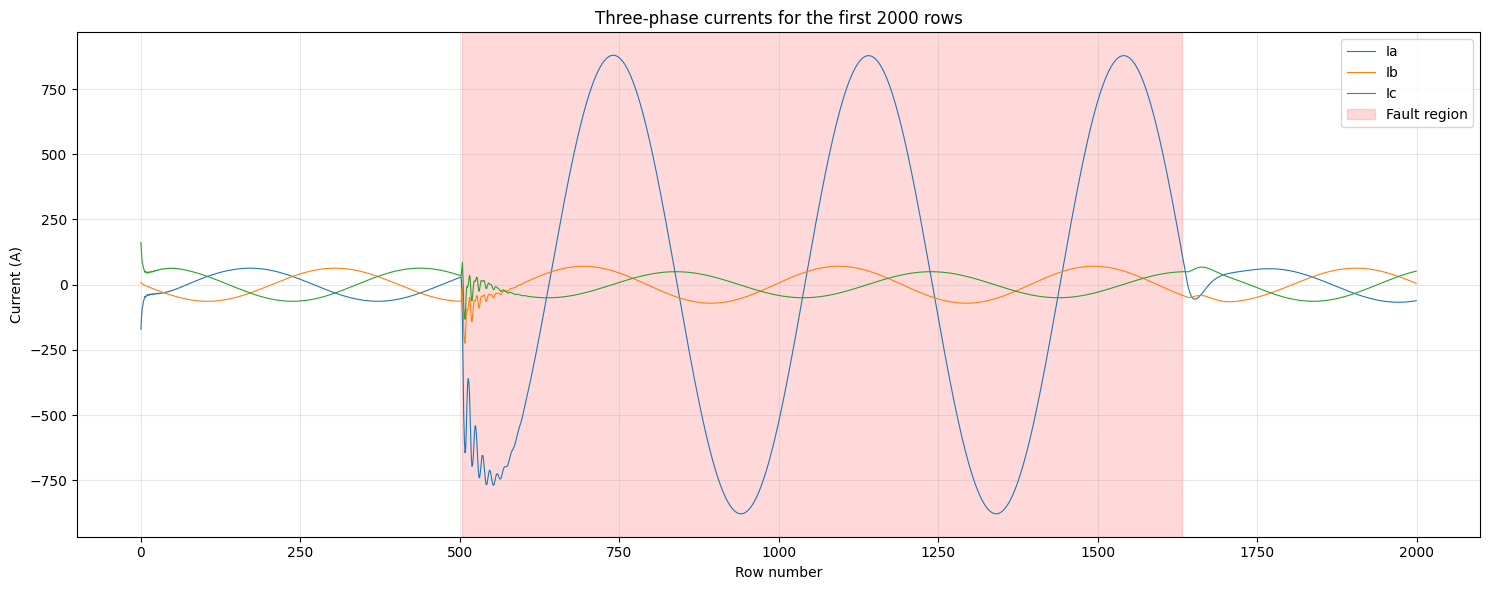

In [8]:
#Plots
plot_df = df.iloc[:2000].reset_index(drop=True)

plt.figure(figsize=(15, 6))

plt.plot(plot_df.index, plot_df["Ia"], label="Ia", linewidth=0.8)
plt.plot(plot_df.index, plot_df["Ib"], label="Ib", linewidth=0.8)
plt.plot(plot_df.index, plot_df["Ic"], label="Ic", linewidth=0.8)

# Shade continuous fault regions
fault_mask = plot_df["fault"].to_numpy() == 1
changes = np.diff(
    np.r_[False, fault_mask, False].astype(int)
)

starts = np.where(changes == 1)[0]
ends = np.where(changes == -1)[0]

for i, (start, end) in enumerate(zip(starts, ends)):
    plt.axvspan(
        start, end - 1,
        color="red", alpha=0.15,
        label="Fault region" if i == 0 else None
    )

plt.xlabel("Row number")
plt.ylabel("Current (A)")
plt.title("Three-phase currents for the first 2000 rows")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("currents_first_2000.png", dpi=150)
plt.show()

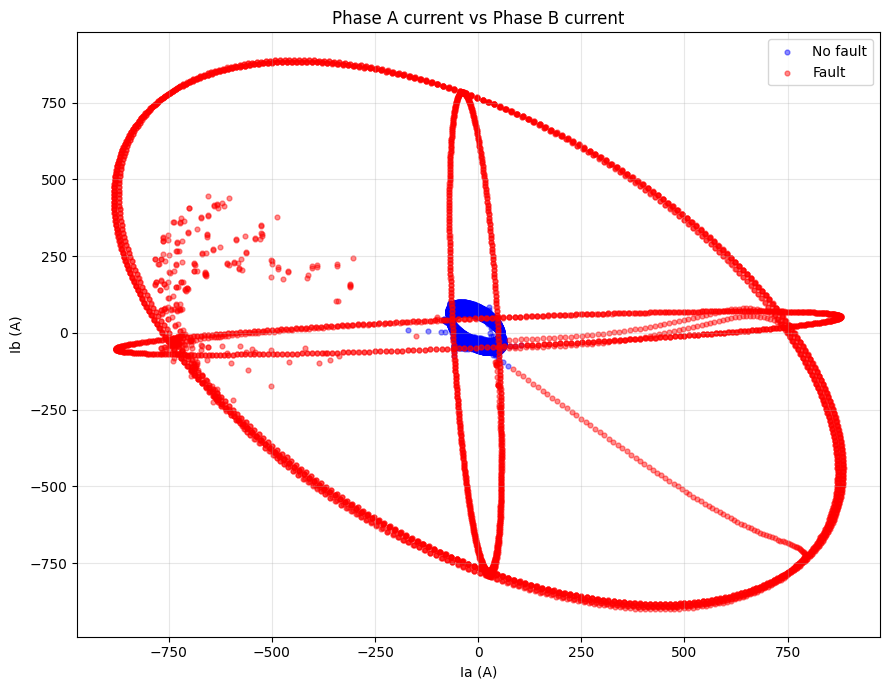

In [9]:
plt.figure(figsize=(9, 7))

for label, name, color in [
    (0, "No fault", "blue"),
    (1, "Fault", "red")
]:
    subset = df[df["fault"] == label]

    plt.scatter(
        subset["Ia"],
        subset["Ib"],
        s=12,
        alpha=0.45,
        label=name,
        c=color
    )

plt.xlabel("Ia (A)")
plt.ylabel("Ib (A)")
plt.title("Phase A current vs Phase B current")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("current_scatter.png", dpi=150)
plt.show()

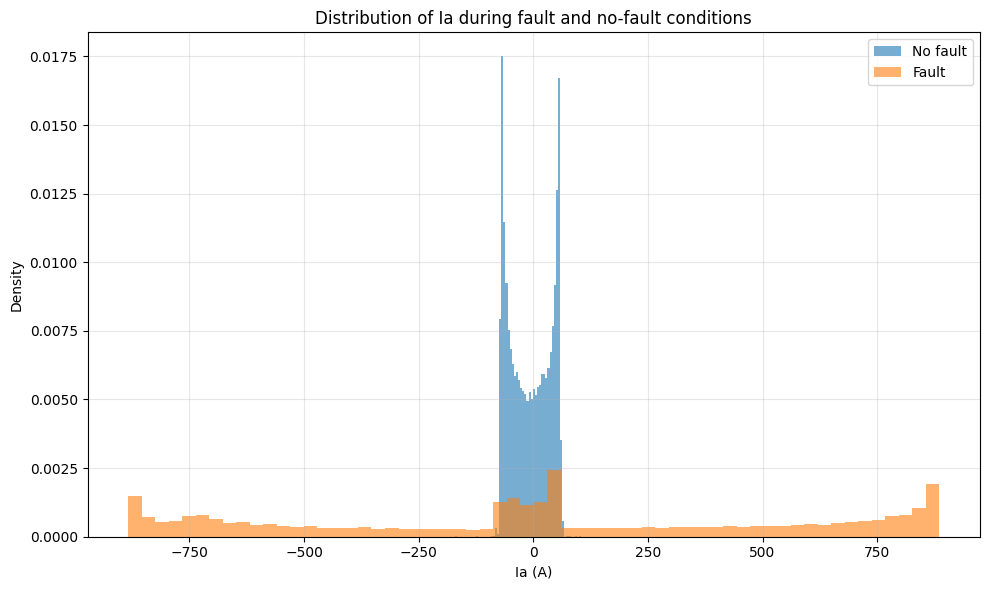

In [10]:
plt.figure(figsize=(10, 6))

plt.hist(
    df.loc[df["fault"] == 0, "Ia"],
    bins=60,
    alpha=0.6,
    label="No fault",
    density=True
)

plt.hist(
    df.loc[df["fault"] == 1, "Ia"],
    bins=60,
    alpha=0.6,
    label="Fault",
    density=True
)

plt.xlabel("Ia (A)")
plt.ylabel("Density")
plt.title("Distribution of Ia during fault and no-fault conditions")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("ia_histogram.png", dpi=150)
plt.show()

In [11]:
#Logistic Regression
X_train_Q_raw = np.column_stack([
    X_train_raw,
    X_train_raw ** 2
])

X_val_Q_raw = np.column_stack([
    X_val_raw,
    X_val_raw ** 2
])

X_test_Q_raw = np.column_stack([
    X_test_raw,
    X_test_raw ** 2
])

# Calculate means and standard deviations from training Set Q
mean_Q = X_train_Q_raw.mean(axis=0)
std_Q = X_train_Q_raw.std(axis=0)

std_Q[std_Q == 0] = 1.0

# Standardise all Set Q splits
X_train_Q = (X_train_Q_raw - mean_Q) / std_Q
X_val_Q = (X_val_Q_raw - mean_Q) / std_Q
X_test_Q = (X_test_Q_raw - mean_Q) / std_Q

print("Set R training shape:", X_train.shape)
print("Set Q training shape:", X_train_Q.shape)

Set R training shape: (7200, 6)
Set Q training shape: (7200, 12)


In [12]:
#Sigmoid Function
def sigmoid(z):
    z = np.clip(z, -500, 500)
    return 1 / (1 + np.exp(-z))

In [13]:
#Hypothesis function
def hypothesis(X, theta):
    return sigmoid(X @ theta)

In [14]:
#Cost function
def cost(X, y, theta):
    h = hypothesis(X, theta)

    h = np.clip(h, 1e-12, 1 - 1e-12)

    return -np.mean(
        y * np.log(h) +
        (1 - y) * np.log(1 - h)
    )

In [15]:
#Batch Gradient Descent
def fit_logistic(X, y, alpha, n_iters):
    theta = np.zeros(X.shape[1])
    cost_history = []

    n = len(y)

    for _ in range(n_iters):
        h = hypothesis(X, theta)

        gradient = (X.T @ (y - h)) / n

        theta = theta + alpha * gradient

        cost_history.append(cost(X, y, theta))

    return theta, np.array(cost_history)

In [16]:
#Prediction Function
def predict(X, theta):
    probabilities = hypothesis(X, theta)
    return (probabilities >= 0.5).astype(int)

In [18]:
#Add intercept columns
def add_intercept(X):
    return np.column_stack([
        np.ones(X.shape[0]),
        X
    ])

X_train_R = add_intercept(X_train)
X_val_R = add_intercept(X_val)
X_test_R = add_intercept(X_test)

X_train_Q = add_intercept(X_train_Q)
X_val_Q = add_intercept(X_val_Q)
X_test_Q = add_intercept(X_test_Q)

print("Set R with intercept:", X_train_R.shape)
print("Set Q with intercept:", X_train_Q.shape)

print("Initial Set R cost:",
      cost(X_train_R, y_train, np.zeros(X_train_R.shape[1])))

print("Initial Set Q cost:",
      cost(X_train_Q, y_train, np.zeros(X_train_Q.shape[1])))

Set R with intercept: (7200, 7)
Set Q with intercept: (7200, 13)
Initial Set R cost: 0.6931471805599452
Initial Set Q cost: 0.6931471805599452


R | alpha = 0.01 | final cost = 0.6771947896608215 | decreases every iteration = True
R | alpha = 0.1 | final cost = 0.677161173060455 | decreases every iteration = True
R | alpha = 1 | final cost = 0.6771611730538888 | decreases every iteration = True
R | alpha = 10 | final cost = 1.343939932014139 | decreases every iteration = False


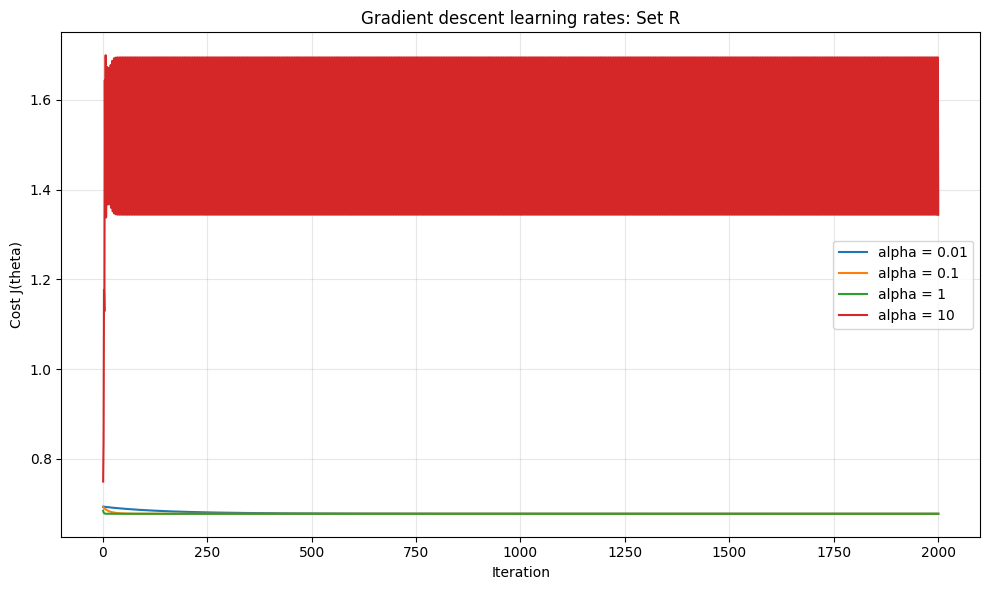

Q | alpha = 0.01 | final cost = 0.20058062446092612 | decreases every iteration = True
Q | alpha = 0.1 | final cost = 0.13996957946776992 | decreases every iteration = True
Q | alpha = 1 | final cost = 0.08898882056478552 | decreases every iteration = True
Q | alpha = 10 | final cost = 0.05343427118405187 | decreases every iteration = True


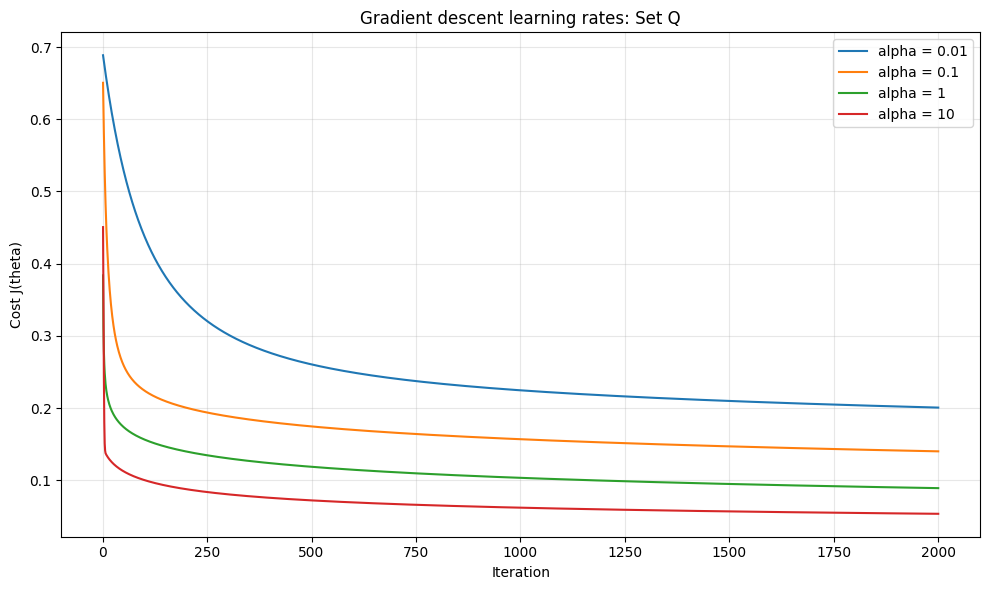

In [19]:
#comparison of learning rates
learning_rates = [0.01, 0.1, 1, 10]
iterations = 2000

cost_histories = {
    "R": {},
    "Q": {}
}

for name, X in [
    ("R", X_train_R),
    ("Q", X_train_Q)
]:
    plt.figure(figsize=(10, 6))

    for alpha in learning_rates:
        theta, history = fit_logistic(
            X, y_train, alpha, iterations
        )

        cost_histories[name][alpha] = history

        plt.plot(
            range(1, iterations + 1),
            history,
            label=f"alpha = {alpha}"
        )

        print(
            name,
            "| alpha =", alpha,
            "| final cost =", history[-1],
            "| decreases every iteration =",
            np.all(np.diff(history) < 0)
        )

    plt.xlabel("Iteration")
    plt.ylabel("Cost J(theta)")
    plt.title(f"Gradient descent learning rates: Set {name}")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(f"cost_curves_{name}.png", dpi=150)
    plt.show()

In [20]:
#training of final logistic models
alpha_R = 1
alpha_Q = 10

theta_R, history_R = fit_logistic(
    X_train_R, y_train, alpha_R, 2000
)

theta_Q, history_Q = fit_logistic(
    X_train_Q, y_train, alpha_Q, 2000
)

train_acc_R = np.mean(
    predict(X_train_R, theta_R) == y_train
)

val_acc_R = np.mean(
    predict(X_val_R, theta_R) == y_val
)

train_acc_Q = np.mean(
    predict(X_train_Q, theta_Q) == y_train
)

val_acc_Q = np.mean(
    predict(X_val_Q, theta_Q) == y_val
)

print("SET R")
print("Chosen alpha:", alpha_R)
print("Final cost:", history_R[-1])
print("Training accuracy:", train_acc_R)
print("Validation accuracy:", val_acc_R)
print("Theta:", theta_R)

print("\nSET Q")
print("Chosen alpha:", alpha_Q)
print("Final cost:", history_Q[-1])
print("Training accuracy:", train_acc_Q)
print("Validation accuracy:", val_acc_Q)
print("Theta:", theta_Q)

SET R
Chosen alpha: 1
Final cost: 0.6771611730538888
Training accuracy: 0.7258333333333333
Validation accuracy: 0.7308333333333333
Theta: [-0.16101209  0.08976488 -0.13667994  0.21707273 -0.05750083  0.05438668
  0.00102553]

SET Q
Chosen alpha: 10
Final cost: 0.05343427118405187
Training accuracy: 0.97875
Validation accuracy: 0.9783333333333334
Theta: [24.92091412  2.32729159 -5.35808387 -1.73650313 -0.53356871  0.41672641
  0.09857963 18.8912383   4.75425591 13.95691804 -6.02763643 -6.46425837
 -6.14074546]


In [21]:
np.save("theta_R.npy", theta_R)
np.save("theta_Q.npy", theta_Q)

In [23]:
#Train and compare SVM models
linear_results = []
linear_models = {}

for C in [0.1, 1, 10, 100]:
    model = SVC(kernel="linear", C=C)

    model.fit(X_train, y_train)

    val_pred = model.predict(X_val)
    val_accuracy = np.mean(val_pred == y_val)

    linear_models[C] = model

    linear_results.append({
        "Kernel": "linear",
        "C": C,
        "Gamma": "-",
        "Validation Accuracy": val_accuracy,
        "Support Vectors": model.n_support_.sum()
    })

linear_table = pd.DataFrame(linear_results)
display(linear_table)

,Kernel,C,Gamma,Validation Accuracy,Support Vectors
0,linear,0.1,-,0.725833,5849
1,linear,1.0,-,0.725833,5845
2,linear,10.0,-,0.725833,5835
3,linear,100.0,-,0.725833,5833


In [24]:
#Train the RBF SVM
rbf_results = []
rbf_models = {}

for C in [0.1, 1, 10, 100]:
    for gamma in [0.1, 1]:
        model = SVC(
            kernel="rbf",
            C=C,
            gamma=gamma
        )

        model.fit(X_train, y_train)

        val_pred = model.predict(X_val)
        val_accuracy = np.mean(val_pred == y_val)

        rbf_models[(C, gamma)] = model

        rbf_results.append({
            "Kernel": "rbf",
            "C": C,
            "Gamma": gamma,
            "Validation Accuracy": val_accuracy,
            "Support Vectors": model.n_support_.sum()
        })

rbf_table = pd.DataFrame(rbf_results)
display(rbf_table)

,Kernel,C,Gamma,Validation Accuracy,Support Vectors
0,rbf,0.1,0.1,0.950000,1347
1,rbf,0.1,1.0,0.980417,848
2,rbf,1.0,0.1,0.975000,723
3,rbf,1.0,1.0,0.991667,482
4,rbf,10.0,0.1,0.992083,381
5,rbf,10.0,1.0,0.996250,342
6,rbf,100.0,0.1,0.995417,174
7,rbf,100.0,1.0,0.996667,266


In [25]:
#combing results
svm_table = pd.concat(
    [linear_table, rbf_table],
    ignore_index=True
)

svm_table = svm_table.sort_values(
    by=["Kernel", "C", "Gamma"],
    ignore_index=True
)

display(
    svm_table.style.format({
        "Validation Accuracy": "{:.4%}"
    })
)

svm_table.to_csv("svm_validation_results.csv", index=False)

,Kernel,C,Gamma,Validation Accuracy,Support Vectors
0,linear,0.100000,-,72.5833%,5849
1,linear,1.000000,-,72.5833%,5845
2,linear,10.000000,-,72.5833%,5835
3,linear,100.000000,-,72.5833%,5833
4,rbf,0.100000,0.100000,95.0000%,1347
5,rbf,0.100000,1.000000,98.0417%,848
6,rbf,1.000000,0.100000,97.5000%,723
7,rbf,1.000000,1.000000,99.1667%,482
8,rbf,10.000000,0.100000,99.2083%,381
9,rbf,10.000000,1.000000,99.6250%,342


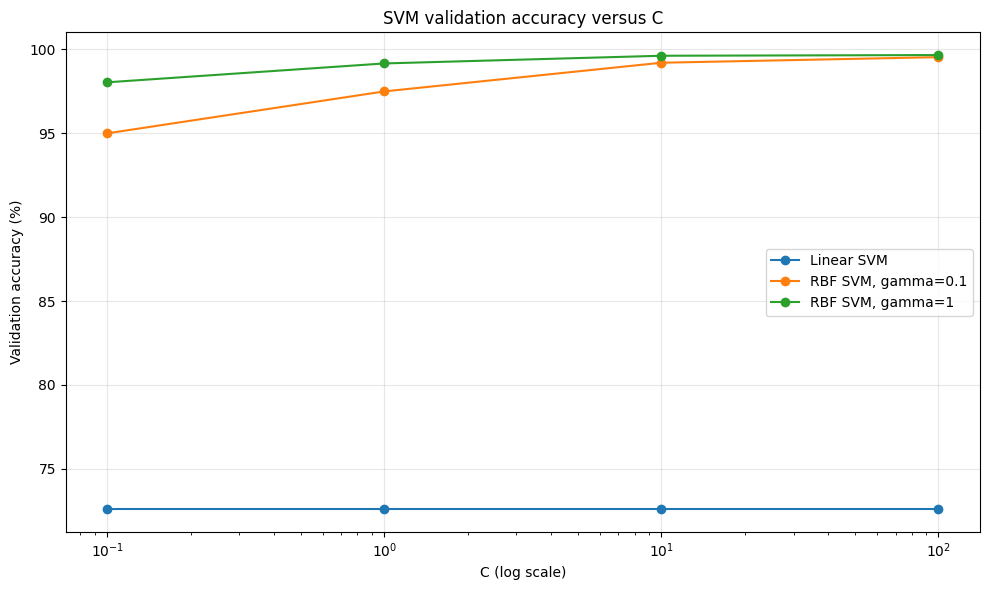

In [26]:
#Plot validation accuracy against C
plt.figure(figsize=(10, 6))

linear_plot = linear_table.sort_values("C")

plt.plot(
    linear_plot["C"],
    linear_plot["Validation Accuracy"] * 100,
    marker="o",
    label="Linear SVM"
)

for gamma in [0.1, 1]:
    subset = rbf_table[
        rbf_table["Gamma"] == gamma
    ].sort_values("C")

    plt.plot(
        subset["C"],
        subset["Validation Accuracy"] * 100,
        marker="o",
        label=f"RBF SVM, gamma={gamma}"
    )

plt.xscale("log")
plt.xlabel("C (log scale)")
plt.ylabel("Validation accuracy (%)")
plt.title("SVM validation accuracy versus C")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("svm_validation_plot.png", dpi=150)
plt.show()

In [27]:
best_linear_C = 10
best_rbf_C = 100
best_rbf_gamma = 1

best_linear_model = linear_models[best_linear_C]
best_rbf_model = rbf_models[(best_rbf_C, best_rbf_gamma)]

joblib.dump(best_linear_model, "best_linear_svm.joblib")
joblib.dump(best_rbf_model, "best_rbf_svm.joblib")

print("Saved best linear SVM")
print("Saved best RBF SVM")

Saved best linear SVM
Saved best RBF SVM


In [28]:
def accuracy(y_true, y_pred):
    return np.mean(y_true == y_pred)


def confusion_matrix(y_true, y_pred):
    tn = np.sum((y_true == 0) & (y_pred == 0))
    fp = np.sum((y_true == 0) & (y_pred == 1))
    fn = np.sum((y_true == 1) & (y_pred == 0))
    tp = np.sum((y_true == 1) & (y_pred == 1))

    return np.array([
        [tn, fp],
        [fn, tp]
    ])

In [29]:
test_predictions = {
    "Logistic Regression Set R":
        predict(X_test_R, theta_R),

    "Logistic Regression Set Q":
        predict(X_test_Q, theta_Q),

    "Linear SVM":
        best_linear_model.predict(X_test),

    "RBF SVM":
        best_rbf_model.predict(X_test)
}

test_results = []

for name, y_pred in test_predictions.items():
    cm = confusion_matrix(y_test, y_pred)

    tn, fp = cm[0]
    fn, tp = cm[1]

    test_results.append({
        "Model": name,
        "Accuracy": accuracy(y_test, y_pred),
        "TN": tn,
        "False Alarms": fp,
        "Missed Faults": fn,
        "TP": tp
    })

    print("\nModel:", name)
    print("Accuracy:", round(accuracy(y_test, y_pred), 6))
    print("Confusion matrix:")
    print(cm)
    print("Missed faults:", fn)

test_table = pd.DataFrame(test_results)

display(
    test_table.style.format({
        "Accuracy": "{:.4%}"
    })
)

test_table.to_csv("test_results.csv", index=False)


Model: Logistic Regression Set R
Accuracy: 0.726364
Confusion matrix:
[[1305    0]
 [ 657  439]]
Missed faults: 657

Model: Logistic Regression Set Q
Accuracy: 0.978759
Confusion matrix:
[[1299    6]
 [  45 1051]]
Missed faults: 45

Model: Linear SVM
Accuracy: 0.73636
Confusion matrix:
[[1305    0]
 [ 633  463]]
Missed faults: 633

Model: RBF SVM
Accuracy: 0.995835
Confusion matrix:
[[1301    4]
 [   6 1090]]
Missed faults: 6


,Model,Accuracy,TN,False Alarms,Missed Faults,TP
0,Logistic Regression Set R,72.6364%,1305,0,657,439
1,Logistic Regression Set Q,97.8759%,1299,6,45,1051
2,Linear SVM,73.6360%,1305,0,633,463
3,RBF SVM,99.5835%,1301,4,6,1090
